## Step 1: Install and imports

In [1]:
!pip install -U ultralytics --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 3.7 MB/s eta 0:00:00


## Step 2: Shared helpers

In [2]:
"""Shared helpers used by notebooks 02, 03 and 04.
"""
import os
import time
import random
import shutil

import numpy as np
import pandas as pd
import cv2

IMG_SIZE = 224
MODALITY_PIXEL = {0: 0, 1: 85, 2: 170, 3: 255}   # CTA, MRA, MRI T1post, MRI T2
MODALITY_NAMES = {0: "CTA", 1: "MRA", 2: "MRI T1post", 3: "MRI T2"}

SPLIT_NAMES = ["70_15_15", "80_10_10", "85_7dot5_7dot5"]
MAIN_SPLIT = "70_15_15"       # model comparison split (largest test set); other splits are ablations in notebook 03

# Colour jitter is disabled on purpose: the images are grayscale-derived and the
# third channel is a constant that encodes the modality, so hue/saturation/value
# changes would only corrupt that signal.
YOLO_COMMON = dict(epochs=50, imgsz=IMG_SIZE, batch=32, patience=15, seed=42,
                   hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, plots=False, exist_ok=True)


# --------------------------------------------------------------------------
# Locating files produced by notebook 01 / 02 (Kaggle nests outputs unpredictably)
# --------------------------------------------------------------------------
def find_file(name, base="/kaggle/input", max_depth=5,
              skip=("rsna-intracranial-aneurysm-detection",
                    "rsna-2025-intracranial-aneurysm-png-224x224")):
    """Walk `base` (bounded depth, skipping the huge raw datasets) and return the shortest match."""
    hits = []
    for root, dirs, files in os.walk(base):
        depth = root[len(base):].count(os.sep)
        dirs[:] = [d for d in dirs if d not in skip] if depth < max_depth else []
        if name in files:
            hits.append(os.path.join(root, name))
    return sorted(hits, key=len)[0] if hits else None


def find_data_root():
    path = find_file("final_df_v2.csv")
    assert path is not None, ("final_df_v2.csv not found. Add the output of notebook 01 "
                              "(Add Input -> Your Work -> Notebook output).")
    return os.path.dirname(path)


def load_split(split_name, data_root):
    """Read split_<name>.csv and attach absolute image paths (image_path in the CSV is relative)."""
    df = pd.read_csv(os.path.join(data_root, f"split_{split_name}.csv"))
    df["abs_path"] = data_root + "/" + df["image_path"]
    return df


# --------------------------------------------------------------------------
# Image construction
# --------------------------------------------------------------------------
def make_modality_image(gray, modality_code):
    """Stack [gray, gray, constant-modality-channel]."""
    h, w = gray.shape
    mod = np.full((h, w), MODALITY_PIXEL.get(int(modality_code), 128), dtype=np.uint8)
    return np.stack([gray, gray, mod], axis=-1)


def make_plain_image(gray):
    return np.stack([gray, gray, gray], axis=-1)


def transform_image_and_boxes(gray, boxes, kind, angle=0.0):
    """Apply orig / flip / rot to a grayscale image and its boxes.

    boxes: list of (xc, yc, w, h) in normalised coordinates.
    Returns (image, boxes). Boxes whose centre leaves the image after rotation are dropped.
    """
    if kind == "orig":
        return gray, list(boxes)
    if kind == "flip":
        return cv2.flip(gray, 1), [(1.0 - x, y, w, h) for x, y, w, h in boxes]
    if kind == "rot":
        h_img, w_img = gray.shape
        M = cv2.getRotationMatrix2D((w_img / 2, h_img / 2), angle, 1.0)
        rot = cv2.warpAffine(gray, M, (w_img, h_img), borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        out = []
        for x, y, w, h in boxes:
            px, py = x * w_img, y * h_img
            nx = (M[0, 0] * px + M[0, 1] * py + M[0, 2]) / w_img
            ny = (M[1, 0] * px + M[1, 1] * py + M[1, 2]) / h_img
            if 0.0 <= nx <= 1.0 and 0.0 <= ny <= 1.0:
                out.append((nx, ny, w, h))
        return rot, out
    raise ValueError(kind)


def image_table(split_df):
    """Collapse the box-level table to one row per image with its list of boxes."""
    rows = []
    for path, g in split_df.groupby("abs_path", sort=False):
        first = g.iloc[0]
        boxes = [(r.x_center, r.y_center, r.box_w, r.box_h) for r in g.itertuples()
                 if pd.notna(r.x_center)]
        rows.append(dict(abs_path=path, SeriesInstanceUID=first["SeriesInstanceUID"],
                         Modality=first["Modality"], modality_code=int(first["modality_code"]),
                         label=int(len(boxes) > 0), boxes=boxes, split=first["split"]))
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------
# YOLO dataset export
# --------------------------------------------------------------------------
def _write_label(path, boxes):
    with open(path, "w") as f:
        f.write("\n".join(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for x, y, w, h in boxes))


def _link_or_copy(src, dst):
    try:
        os.link(src, dst)          # hard link: no extra disk space for oversampled duplicates
    except OSError:
        shutil.copy(src, dst)


def build_yolo_dataset(split_df, root, modality_aware=True, balance=True,
                       rot_deg=15, use_flip=True, seed=42):
    """Export one split to YOLO format.

    train: orig (+ flip) (+ rotation by +-rot_deg) variants of every image, all boxes of an
           image kept together; optional modality oversampling with hard links.
    val/test: original images only.
    Returns (yaml_path, stats_dict).
    """
    rng = random.Random(seed)
    if os.path.exists(root):
        shutil.rmtree(root)
    img_tab = image_table(split_df)

    def render(gray, code):
        return make_modality_image(gray, code) if modality_aware else make_plain_image(gray)

    stats, file_modality = {}, {}
    for part in ["train", "val", "test"]:
        os.makedirs(f"{root}/images/{part}", exist_ok=True)
        os.makedirs(f"{root}/labels/{part}", exist_ok=True)
        sub = img_tab[img_tab["split"] == part].reset_index(drop=True)
        n_files = 0
        for k, r in sub.iterrows():
            gray = cv2.imread(r["abs_path"], cv2.IMREAD_GRAYSCALE)
            if gray is None:
                continue
            kinds = ["orig"]
            if part == "train":
                if use_flip:
                    kinds.append("flip")
                if rot_deg and rot_deg > 0:
                    kinds.append("rot")
            angle = rng.choice([-rot_deg, rot_deg]) if (part == "train" and rot_deg) else 0
            for kind in kinds:
                img_t, boxes_t = transform_image_and_boxes(gray, r["boxes"], kind, angle)
                if r["label"] == 1 and len(boxes_t) == 0:
                    continue                       # rotation pushed every box out of the frame
                base = f"{r['SeriesInstanceUID']}_{k}_{kind}"
                cv2.imwrite(f"{root}/images/{part}/{base}.png", render(img_t, r["modality_code"]))
                _write_label(f"{root}/labels/{part}/{base}.txt", boxes_t)
                file_modality[(part, base)] = r["Modality"]
                n_files += 1
        stats[part] = dict(images=n_files,
                           positive_images=int(sub["label"].sum()) if part != "train" else None,
                           boxes=int(sub["boxes"].apply(len).sum()) if part != "train" else None,
                           series=int(sub["SeriesInstanceUID"].nunique()))

    if balance:
        by_mod = {}
        for (part, base), mod in file_modality.items():
            if part == "train":
                by_mod.setdefault(mod, []).append(base)
        target = max(len(v) for v in by_mod.values())
        for mod, bases in by_mod.items():
            extra = rng.choices(bases, k=target - len(bases)) if len(bases) < target else []
            for i, base in enumerate(extra):
                _link_or_copy(f"{root}/images/train/{base}.png", f"{root}/images/train/{base}_dup{i}.png")
                _link_or_copy(f"{root}/labels/train/{base}.txt", f"{root}/labels/train/{base}_dup{i}.txt")
        stats["train_balanced_per_modality"] = target

    stats["train"]["images"] = len(os.listdir(f"{root}/images/train"))
    stats["train"]["positive_images"] = int(sum(
        os.path.getsize(f"{root}/labels/train/{f}") > 0 for f in os.listdir(f"{root}/labels/train")))
    pd.DataFrame([dict(part=p, base=b, Modality=m) for (p, b), m in file_modality.items()]
                 ).to_csv(f"{root}/file_modality.csv", index=False)
    yaml_path = f"{root}/data.yaml"
    with open(yaml_path, "w") as f:
        f.write(f"path: {root}\ntrain: images/train\nval: images/val\ntest: images/test\n\n"
                f"names:\n  0: aneurysm\n")
    return yaml_path, stats


def make_modality_subsets(root, out_root):
    """Hard-link the test images of each modality into their own folder with a yaml (for per-modality eval)."""
    fm = pd.read_csv(f"{root}/file_modality.csv")
    fm = fm[fm["part"] == "test"]
    yamls = {}
    for mod, g in fm.groupby("Modality"):
        tag = mod.replace(" ", "_")
        for sub in ["images/test", "labels/test", "images/val", "labels/val"]:
            os.makedirs(f"{out_root}/{tag}/{sub}", exist_ok=True)
        for base in g["base"]:
            for d, ext in [("images", "png"), ("labels", "txt")]:
                for part in ["test", "val"]:
                    dst = f"{out_root}/{tag}/{d}/{part}/{base}.{ext}"
                    if not os.path.exists(dst):
                        _link_or_copy(f"{root}/{d}/test/{base}.{ext}", dst)
        y = f"{out_root}/{tag}/data.yaml"
        with open(y, "w") as f:
            f.write(f"path: {out_root}/{tag}\ntrain: images/test\nval: images/val\ntest: images/test\n\n"
                    f"names:\n  0: aneurysm\n")
        yamls[mod] = (y, len(g))
    return yamls


# --------------------------------------------------------------------------
# Result bookkeeping (lets a crashed notebook resume)
# --------------------------------------------------------------------------
def done_ids(csv_path, col="run_id"):
    return set(pd.read_csv(csv_path)[col]) if os.path.exists(csv_path) else set()


def append_row(csv_path, row):
    """Append one result row; columns are aligned even if the new row has extra/missing keys."""
    new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        new = pd.concat([pd.read_csv(csv_path), new], ignore_index=True)
    new.to_csv(csv_path, index=False)


def train_eval_yolo(weights, data_yaml, run_id, project, extra=None):
    """Train, then evaluate best.pt on val and test. Returns (metrics_row, best_pt_path)."""
    from ultralytics import YOLO
    params = dict(YOLO_COMMON)
    params.update(extra or {})
    imgsz = int(params["imgsz"])
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=data_yaml, project=project, name=run_id, **params)
    best_path = str(model.trainer.best)
    minutes = (time.time() - t0) / 60
    best = YOLO(best_path)
    out = {}
    for split in ["val", "test"]:
        r = best.val(data=data_yaml, split=split, imgsz=imgsz, project=project,
                     name=f"{run_id}_{split}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        out[split] = dict(map50=float(r.box.map50), map5095=float(r.box.map), precision=p, recall=rec,
                          f1=(2 * p * rec / (p + rec)) if (p + rec) > 0 else 0.0)
    row = dict(run_id=run_id, imgsz=imgsz, train_minutes=round(minutes, 1))
    for split in ["val", "test"]:
        for k, v in out[split].items():
            row[f"{split}_{k}"] = round(v, 4)
    return row, best_path


def conf_sweep(best_path, data_yaml, project, confs=(0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5), imgsz=IMG_SIZE):
    from ultralytics import YOLO
    model = YOLO(best_path)
    rows = []
    for c in confs:
        r = model.val(data=data_yaml, split="test", imgsz=imgsz, conf=c, project=project,
                      name=f"conf_{c}", exist_ok=True, verbose=False, plots=False)
        p, rec = float(r.box.mp), float(r.box.mr)
        rows.append(dict(conf=c, map50=round(float(r.box.map50), 4), map5095=round(float(r.box.map), 4),
                         precision=round(p, 4), recall=round(rec, 4),
                         f1=round(2 * p * rec / (p + rec), 4) if (p + rec) > 0 else 0.0))
    return pd.DataFrame(rows)

## Step 3: Configuration, data location and resume

In [3]:
import json
import matplotlib.pyplot as plt

OUT = "/kaggle/working"
PROJECT = f"{OUT}/runs"
RESULTS_CSV = f"{OUT}/det_results_{MAIN_SPLIT}.csv"
os.makedirs(f"{OUT}/weights", exist_ok=True)
os.makedirs(f"{OUT}/curves", exist_ok=True)

DATA_ROOT = find_data_root()
print("Data root:", DATA_ROOT)

RUNS = [
    dict(run_id="M5_yolo26s",      name="M5 YOLO26s (balanced)",       weights="yolo26s.pt", data="mod_bal",     extra={}),
    dict(run_id="M3_balanced",     name="M3 Balanced",                 weights="yolo26n.pt", data="mod_bal",     extra={}),
    dict(run_id="M4_imgsz448",     name="M4 Balanced + 448 px input",  weights="yolo26n.pt", data="mod_bal",     extra=dict(imgsz=448)),
    dict(run_id="M6_yolo26m",      name="M6 YOLO26m (balanced)",       weights="yolo26m.pt", data="mod_bal",     extra={}),
    dict(run_id="M2_modality",     name="M2 Modality-aware",           weights="yolo26n.pt", data="mod_unbal",   extra={}),
    dict(run_id="M1_baseline",     name="M1 Baseline",                 weights="yolo26n.pt", data="plain_unbal", extra={}),
    dict(run_id="M7_no_mosaic",    name="M7 Balanced, no mosaic",      weights="yolo26n.pt", data="mod_bal",     extra=dict(mosaic=0.0), optional=True),
]
DATASETS = dict(
    mod_bal=dict(modality_aware=True, balance=True),
    mod_unbal=dict(modality_aware=True, balance=False),
    plain_unbal=dict(modality_aware=False, balance=False),
)
ONLY = None            # e.g. ["M5_yolo26s", "M3_balanced"]; None runs M1-M6 (M7 only when named here)
SPLIT = MAIN_SPLIT

# Seed from a previous session's output (if it was added as an input)
prev = find_file(f"det_results_{MAIN_SPLIT}.csv")
if prev and not os.path.exists(RESULTS_CSV):
    prev_dir = os.path.dirname(prev)
    for fn in os.listdir(prev_dir):
        src = os.path.join(prev_dir, fn)
        if fn.endswith(".csv") or fn.endswith(".json"):
            shutil.copy(src, OUT)
    for sub in ["weights", "curves"]:
        if os.path.isdir(os.path.join(prev_dir, sub)):
            for fn in os.listdir(os.path.join(prev_dir, sub)):
                shutil.copy(os.path.join(prev_dir, sub, fn), f"{OUT}/{sub}/{fn}")
    print("Resumed from", prev_dir, "| finished runs:", sorted(done_ids(RESULTS_CSV)))

split_df = load_split(SPLIT, DATA_ROOT)
print(split_df.groupby("split")["abs_path"].nunique().to_string())

Data root: /kaggle/input/notebooks/workplace123/1-data-pipeline
split
test      674
train    3050
val       648


## Step 4: Train and evaluate

In [4]:
def extras_for_m5(root, best_path):
    sweep = conf_sweep(best_path, f"{root}/data.yaml", PROJECT)
    sweep.to_csv(f"{OUT}/det_conf_sweep_M5.csv", index=False)
    print(sweep.to_string(index=False))
    from ultralytics import YOLO
    rows = []
    subsets = make_modality_subsets(root, f"{OUT}/_mod_subsets")
    for mod, (yaml_path, n_img) in subsets.items():
        r = YOLO(best_path).val(data=yaml_path, split="test", imgsz=IMG_SIZE, project=PROJECT,
                                name=f"mod_{mod}", exist_ok=True, verbose=False, plots=False)
        rows.append(dict(modality=mod, test_images=n_img, map50=round(float(r.box.map50), 4),
                         map5095=round(float(r.box.map), 4), precision=round(float(r.box.mp), 4),
                         recall=round(float(r.box.mr), 4)))
    shutil.rmtree(f"{OUT}/_mod_subsets", ignore_errors=True)
    pd.DataFrame(rows).to_csv(f"{OUT}/det_per_modality_M5.csv", index=False)
    print(pd.DataFrame(rows).to_string(index=False))

order = ["mod_bal", "mod_unbal", "plain_unbal"]
for key in order:
    plan = [r for r in RUNS if r["data"] == key and
            ((ONLY is None and not r.get("optional")) or (ONLY is not None and r["run_id"] in ONLY))]
    pending = [r for r in plan if r["run_id"] not in done_ids(RESULTS_CSV)]
    need_extras = (key == "mod_bal" and any(r["run_id"] == "M5_yolo26s" for r in plan)
                   and not os.path.exists(f"{OUT}/det_conf_sweep_M5.csv")
                   and os.path.exists(f"{OUT}/weights/M5_yolo26s_best.pt"))
    if not pending and not need_extras:
        continue
    root = f"{OUT}/yolo_{key}"
    yaml_path, stats = build_yolo_dataset(split_df, root, rot_deg=15, **DATASETS[key])
    json.dump(stats, open(f"{OUT}/det_dataset_stats_{key}.json", "w"), indent=2)
    print(f"[{key}]", stats)
    for r in pending:
        print(f"\n=== {r['run_id']} ===")
        row, best_path = train_eval_yolo(r["weights"], yaml_path, r["run_id"], PROJECT, r["extra"])
        row.update(name=r["name"], weights=r["weights"], dataset=key,
                   test_images=stats["test"]["images"], test_boxes=stats["test"]["boxes"])
        shutil.copy(best_path, f"{OUT}/weights/{r['run_id']}_best.pt")
        res_csv = f"{PROJECT}/{r['run_id']}/results.csv"
        if os.path.exists(res_csv):
            shutil.copy(res_csv, f"{OUT}/curves/{r['run_id']}_results.csv")
        append_row(RESULTS_CSV, row)
        print({k: row[k] for k in ["run_id", "test_map50", "test_map5095", "test_precision", "test_recall", "train_minutes"]})
        if r["run_id"] == "M5_yolo26s":
            extras_for_m5(root, best_path)
    if need_extras and not any(r["run_id"] == "M5_yolo26s" for r in pending):
        extras_for_m5(root, f"{OUT}/weights/M5_yolo26s_best.pt")
    shutil.rmtree(root, ignore_errors=True)
    shutil.rmtree(PROJECT, ignore_errors=True)
print("Finished:", sorted(done_ids(RESULTS_CSV)))

[mod_bal] {'train': {'images': 16980, 'positive_images': 6790, 'boxes': None, 'series': 2816}, 'val': {'images': 648, 'positive_images': 303, 'boxes': 309, 'series': 603}, 'test': {'images': 674, 'positive_images': 327, 'boxes': 332, 'series': 604}, 'train_balanced_per_modality': 4245}

=== M5_yolo26s ===
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, c

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50       1.6G      2.064      2.269   0.008731         11        224: 100% ━━━━━━━━━━━━ 531/531 5.4it/s 1:38
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.7it/s 1.6s
                   all        648        309      0.428      0.359      0.389      0.186

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      1.62G      2.091      2.317   0.008759         12        224: 100% ━━━━━━━━━━━━ 531/531 6.1it/s 1:27
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.2it/s 1.8s
                   all        648        309      0.284      0.374      0.273      0.129

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      1.62G      2.154      2.331   0.009099          9        224: 100% ━━━━━━━━━━━━ 531/531 6.2it/s 1:26
                 Class     Images  Instances      Box(P 

## Step 5: Results table and figures

Detector that notebook 04 will use (highest validation mAP50): M4_imgsz448
                      name  test_map50  test_map5095  test_precision  test_recall  test_f1  val_map50  imgsz  train_minutes
               M1 Baseline      0.5586        0.3558          0.5485       0.5271   0.5376     0.5761    224           32.0
         M2 Modality-aware      0.5525        0.3534          0.5844       0.4970   0.5372     0.5947    224           32.5
               M3 Balanced      0.5414        0.3452          0.5626       0.5060   0.5328     0.5432    224           65.6
M4 Balanced + 448 px input      0.5656        0.3970          0.6184       0.5272   0.5692     0.6491    448           77.4
     M5 YOLO26s (balanced)      0.5409        0.3462          0.6748       0.4669   0.5519     0.5900    224           74.9
     M6 YOLO26m (balanced)      0.5643        0.3640          0.5842       0.5883   0.5863     0.5632    224          102.3


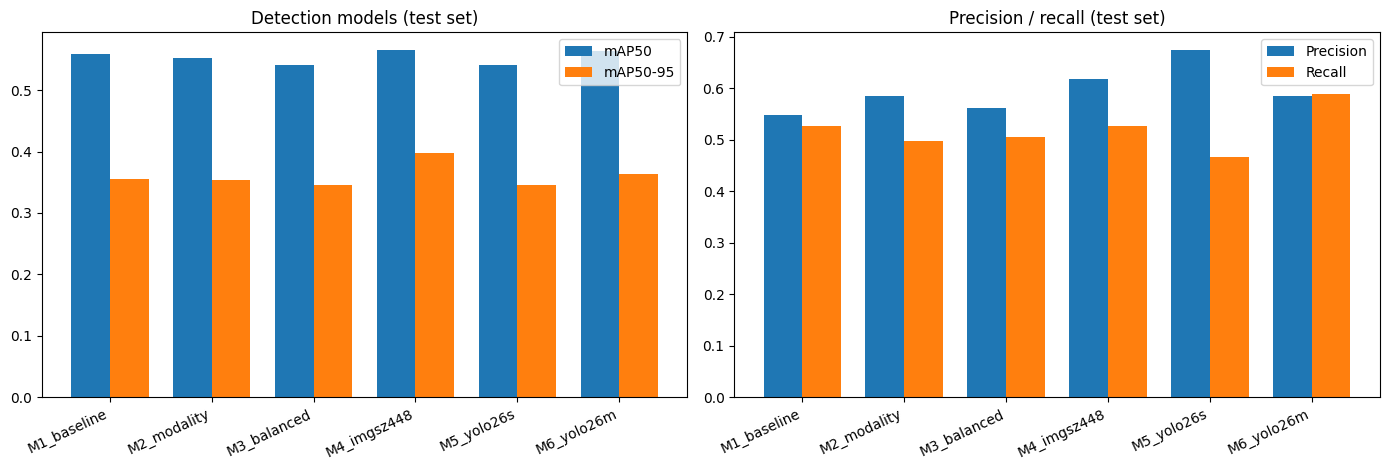

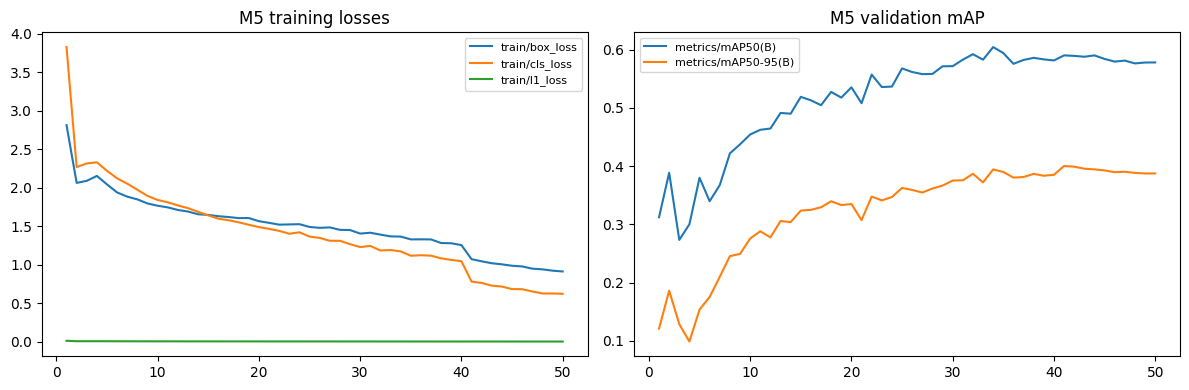

In [5]:
res = pd.read_csv(RESULTS_CSV).drop_duplicates("run_id", keep="last").sort_values("run_id").reset_index(drop=True)
cols = ["name", "test_map50", "test_map5095", "test_precision", "test_recall", "test_f1", "val_map50", "imgsz", "train_minutes"]
best_by_val = res.sort_values("val_map50", ascending=False).iloc[0]["run_id"]
print("Detector that notebook 04 will use (highest validation mAP50):", best_by_val)
print(res[cols].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(res))
w = 0.38
axes[0].bar(x - w / 2, res["test_map50"], w, label="mAP50")
axes[0].bar(x + w / 2, res["test_map5095"], w, label="mAP50-95")
axes[0].set_xticks(x)
axes[0].set_xticklabels(res["run_id"], rotation=25, ha="right")
axes[0].set_title("Detection models (test set)")
axes[0].legend()
axes[1].bar(x - w / 2, res["test_precision"], w, label="Precision")
axes[1].bar(x + w / 2, res["test_recall"], w, label="Recall")
axes[1].set_xticks(x)
axes[1].set_xticklabels(res["run_id"], rotation=25, ha="right")
axes[1].set_title("Precision / recall (test set)")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fig_detection_models.png", dpi=150)
plt.show()

curve = f"{OUT}/curves/M5_yolo26s_results.csv"
if os.path.exists(curve):
    c = pd.read_csv(curve)
    c.columns = [s.strip() for s in c.columns]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for col in [k for k in c.columns if "loss" in k and k.startswith("train")]:
        axes[0].plot(c["epoch"], c[col], label=col)
    axes[0].set_title("M5 training losses")
    axes[0].legend(fontsize=8)
    for col in [k for k in c.columns if "mAP50" in k]:
        axes[1].plot(c["epoch"], c[col], label=col)
    axes[1].set_title("M5 validation mAP")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{OUT}/fig_M5_training_curves.png", dpi=150)
    plt.show()